In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from IPython.display import display

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


In [16]:
# Define states
states = ['A', 'B', 'C', 'G']

# Define actions
actions = {
    'A': ['Left', 'Right'],
    'B': ['Left', 'Right'],
    'C': ['Left', 'Right'],
    'G': []
}

# Discount factor
gamma = 0.9

# Define transition model
# Format: (current_state, action): (next_state, reward)

transitions = {
    ('A', 'Right'): ('B', 2),
    ('A', 'Left'): ('C', 1),

    ('B', 'Right'): ('G', 10),
    ('B', 'Left'): ('A', -1),

    ('C', 'Right'): ('G', 8),
    ('C', 'Left'): ('A', -1)
}

# Define deterministic policy
policy = {
    'A': 'Right',
    'B': 'Right',
    'C': 'Right'
}

print("States:", states)
print("Actions:", actions)
print("Discount Factor:", gamma)
print("Policy:", policy)

States: ['A', 'B', 'C', 'G']
Actions: {'A': ['Left', 'Right'], 'B': ['Left', 'Right'], 'C': ['Left', 'Right'], 'G': []}
Discount Factor: 0.9
Policy: {'A': 'Right', 'B': 'Right', 'C': 'Right'}


In [17]:
transition_data = []

for (state, action), (next_state, reward) in transitions.items():

    transition_data.append({
        'Current State': state,
        'Action': action,
        'Next State': next_state,
        'Probability': 1.0,
        'Reward': reward
    })

transition_df = pd.DataFrame(transition_data)

display(transition_df)

,Current State,Action,Next State,Probability,Reward
0,A,Right,B,1.0,2
1,A,Left,C,1.0,1
2,B,Right,G,1.0,10
3,B,Left,A,1.0,-1
4,C,Right,G,1.0,8
5,C,Left,A,1.0,-1


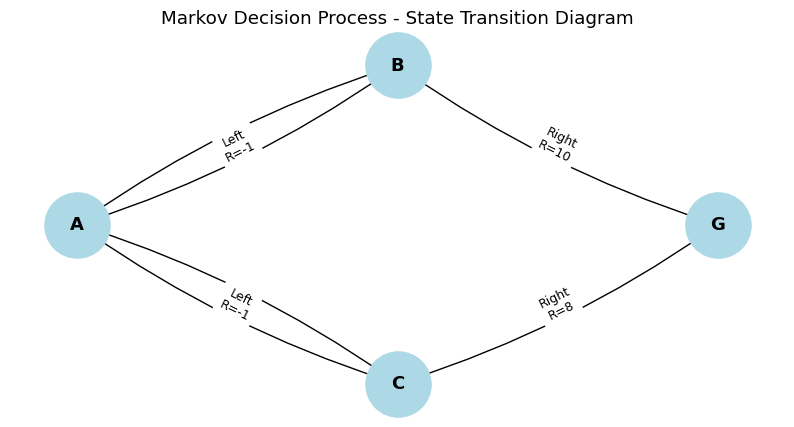

In [18]:
G = nx.DiGraph()

for (state, action), (next_state, reward) in transitions.items():

    G.add_edge(
        state,
        next_state,
        label=f"{action}\nR={reward}"
    )

pos = {
    'A': (0, 0),
    'B': (2, 1),
    'C': (2, -1),
    'G': (4, 0)
}

plt.figure(figsize=(10, 5))

nx.draw_networkx_nodes(
    G, pos,
    node_size=2200,
    node_color='lightblue'
)

nx.draw_networkx_labels(
    G, pos,
    font_size=13,
    font_weight='bold'
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=20,
    connectionstyle='arc3,rad=0.08'
)

edge_labels = nx.get_edge_attributes(G, 'label')

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("Markov Decision Process - State Transition Diagram")
plt.axis('off')
plt.show()

In [19]:
def step(state, action):

    if state == 'G':
        return 'G', 0, True

    if (state, action) not in transitions:
        raise ValueError("Invalid state-action pair")

    next_state, reward = transitions[(state, action)]

    done = next_state == 'G'

    return next_state, reward, done


# Test the environment
current_state = 'A'
action = 'Right'

next_state, reward, done = step(current_state, action)

print("Current State:", current_state)
print("Action:", action)
print("Next State:", next_state)
print("Reward:", reward)
print("Terminal:", done)

Current State: A
Action: Right
Next State: B
Reward: 2
Terminal: False


In [20]:
V = {
    state: 0.0 for state in states
}

# Perform iterative policy evaluation
iterations = 10

history = []

for iteration in range(iterations):

    new_V = V.copy()

    for state in states:

        if state == 'G':
            new_V[state] = 0
            continue

        action = policy[state]

        next_state, reward = transitions[(state, action)]

        new_V[state] = reward + gamma * V[next_state]

    V = new_V

    history.append(V.copy())

    print(f"Iteration {iteration + 1}: {V}")

Iteration 1: {'A': 2.0, 'B': 10.0, 'C': 8.0, 'G': 0}
Iteration 2: {'A': 11.0, 'B': 10.0, 'C': 8.0, 'G': 0}
Iteration 3: {'A': 11.0, 'B': 10.0, 'C': 8.0, 'G': 0}
Iteration 4: {'A': 11.0, 'B': 10.0, 'C': 8.0, 'G': 0}
Iteration 5: {'A': 11.0, 'B': 10.0, 'C': 8.0, 'G': 0}
Iteration 6: {'A': 11.0, 'B': 10.0, 'C': 8.0, 'G': 0}
Iteration 7: {'A': 11.0, 'B': 10.0, 'C': 8.0, 'G': 0}
Iteration 8: {'A': 11.0, 'B': 10.0, 'C': 8.0, 'G': 0}
Iteration 9: {'A': 11.0, 'B': 10.0, 'C': 8.0, 'G': 0}
Iteration 10: {'A': 11.0, 'B': 10.0, 'C': 8.0, 'G': 0}


In [21]:
print("Final State-Value Function")

for state in states:

    print(f"V({state}) = {V[state]:.4f}")

Final State-Value Function
V(A) = 11.0000
V(B) = 10.0000
V(C) = 8.0000
V(G) = 0.0000


In [22]:
q_values = []

for (state, action), (next_state, reward) in transitions.items():

    q = reward + gamma * V[next_state]

    q_values.append({
        'State': state,
        'Action': action,
        'Q Value': q
    })

q_df = pd.DataFrame(q_values)

display(q_df)

,State,Action,Q Value
0,A,Right,11.0
1,A,Left,8.2
2,B,Right,10.0
3,B,Left,8.9
4,C,Right,8.0
5,C,Left,8.9


In [23]:
policies = {

    'Policy 1': {
        'A': 'Right',
        'B': 'Right',
        'C': 'Right'
    },

    'Policy 2': {
        'A': 'Left',
        'B': 'Right',
        'C': 'Right'
    }
}


def evaluate_policy(policy, gamma=0.9, theta=0.000001):

    values = {state: 0.0 for state in states}

    while True:

        delta = 0
        new_values = values.copy()

        for state in states:

            if state == 'G':
                continue

            action = policy[state]

            next_state, reward = transitions[(state, action)]

            new_values[state] = reward + gamma * values[next_state]

            delta = max(
                delta,
                abs(new_values[state] - values[state])
            )

        values = new_values

        if delta < theta:
            break

    return values


comparison = []

for policy_name, current_policy in policies.items():

    values = evaluate_policy(current_policy)

    comparison.append({
        'Policy': policy_name,
        'V(A)': values['A'],
        'V(B)': values['B'],
        'V(C)': values['C']
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

,Policy,V(A),V(B),V(C)
0,Policy 1,11.0,10.0,8.0
1,Policy 2,8.2,10.0,8.0


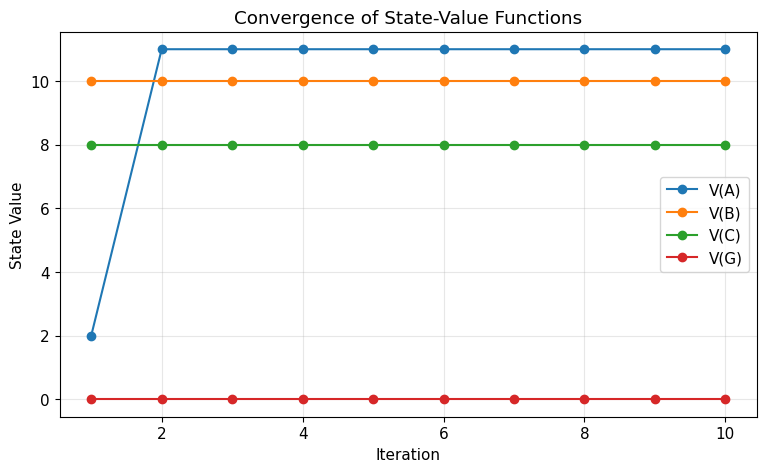

In [24]:
iterations = range(1, len(history) + 1)

plt.figure(figsize=(9, 5))

for state in states:

    values = [item[state] for item in history]

    plt.plot(
        iterations,
        values,
        marker='o',
        label=f'V({state})'
    )

plt.xlabel("Iteration")
plt.ylabel("State Value")

plt.title("Convergence of State-Value Functions")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [25]:
stochastic_transitions = {

    ('A', 'Right'): [
        ('B', 0.8, 2),
        ('C', 0.2, 2)
    ],

    ('A', 'Left'): [
        ('C', 1.0, 1)
    ],

    ('B', 'Right'): [
        ('G', 1.0, 10)
    ],

    ('B', 'Left'): [
        ('A', 1.0, -1)
    ],

    ('C', 'Right'): [
        ('G', 1.0, 8)
    ],

    ('C', 'Left'): [
        ('A', 1.0, -1)
    ]
}


def evaluate_stochastic_policy(policy, gamma=0.9, theta=0.000001):

    values = {state: 0.0 for state in states}

    while True:

        delta = 0
        new_values = values.copy()

        for state in states:

            if state == 'G':
                continue

            action = policy[state]

            outcomes = stochastic_transitions[(state, action)]

            expected_value = 0

            for next_state, probability, reward in outcomes:

                expected_value += probability * (
                    reward + gamma * values[next_state]
                )

            new_values[state] = expected_value

            delta = max(
                delta,
                abs(new_values[state] - values[state])
            )

        values = new_values

        if delta < theta:
            break

    return values


stochastic_values = evaluate_stochastic_policy(policy)

print("Stochastic MDP State Values")

for state, value in stochastic_values.items():

    print(f"V({state}) = {value:.4f}")

Stochastic MDP State Values
V(A) = 10.6400
V(B) = 10.0000
V(C) = 8.0000
V(G) = 0.0000


In [26]:
deterministic_values = evaluate_policy(policy)

comparison = pd.DataFrame({

    'State': states,

    'Deterministic MDP': [
        deterministic_values[s] for s in states
    ],

    'Stochastic MDP': [
        stochastic_values[s] for s in states
    ]

})

display(comparison)

,State,Deterministic MDP,Stochastic MDP
0,A,11.0,10.64
1,B,10.0,10.00
2,C,8.0,8.00
3,G,0.0,0.00
